# ТК 9 (ПР5): многослойный персептрон и обратное распространение ошибки
Нейрон - это базовый вычислительный элемент сети, который суммирует входные сигналы, взвешенные по весам связей, и добавляет смещение.

Веса - это коэффициенты связей, определяющие вклад каждого входа в выход нейрона; смещением (bias) называют добавочный параметр, сдвигающий суммарный сигнал независимо от входов.

Ниже приведены пошаговые эксперименты: от одного нейрона к полносвязной сети, функциям активации, потерь и обратному распространению ошибки.

## Импорты

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

## Нейрон

Схема ниже показывает классическую структуру нейрона: входы $x_i$, веса $w_i$, сумматор и смещение $b$. На изображении видно, как входные сигналы взвешиваются и суммируются перед выдачей результата.

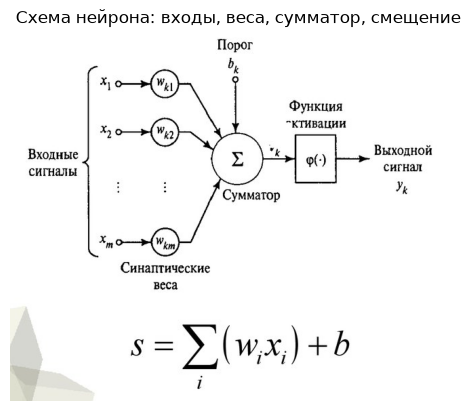

In [2]:
img = mpimg.imread('sources/img/Neuron.png')
plt.imshow(img)
plt.title('Схема нейрона: входы, веса, сумматор, смещение')
plt.axis('off')
plt.show()

In [3]:
class Neuron:
  def __init__(self, weights, bias):
    self.weights = weights
    self.bias = bias

  def forward(self, input):
    return torch.dot(self.weights, input) + self.bias

In [4]:
inputs = torch.tensor([1.0, 2.0, 3.0, 2.5])

weights = torch.tensor([0.2, 0.8, -0.5, 1.0])
bias = 2.0

neuron = Neuron(weights, bias)
neuron.forward(inputs)

tensor(4.8000)

## Слой

Слоем называют группу нейронов, получающих одни и те же входы и выдающих вектор выходов.

На схеме слоя каждая строка весов соответствует отдельному нейрону, а вектор смещений добавляется ко всем выходам одновременно.

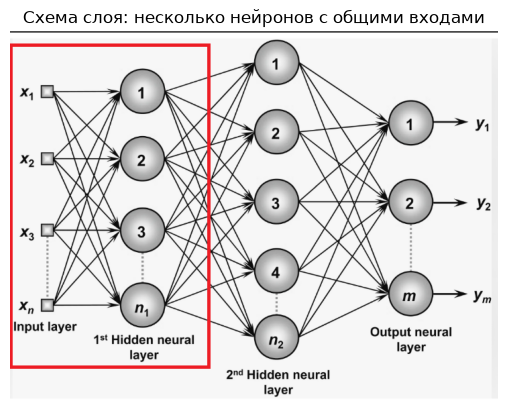

In [5]:
img = mpimg.imread('sources/img/Layer.png')
plt.imshow(img)
plt.title('Схема слоя: несколько нейронов с общими входами')
plt.axis('off')
plt.show()

In [6]:
class Layer:
  def __init__(self, weights, biases):
    self.weights = weights
    self.biases = biases

  def forward(self, input):
    return torch.mv(self.weights, input) + self.biases

In [7]:
inputs = torch.tensor([1.0, 2.0, 3.0, 2.5])
weights = torch.tensor([[0.2, 0.8, -0.5, 1.0],
           [0.5, -0.91, 0.26, -0.5],
           [-0.26, -0.27, 0.17, 0.87]])

biases = torch.tensor([2.0, 3.0, 0.5])

layer = Layer(weights, biases)
layer.forward(inputs)

tensor([4.8000, 1.2100, 2.3850])

## Слой (batch)

Батчем (batch, партия) называют матрицу из нескольких примеров, обрабатываемых слоем за одно матричное умножение.

В режиме batch входы представлены матрицей размера (число примеров, число признаков), поэтому вместо умножения вектора на матрицу используется матричное произведение `inputs @ weights.T`.

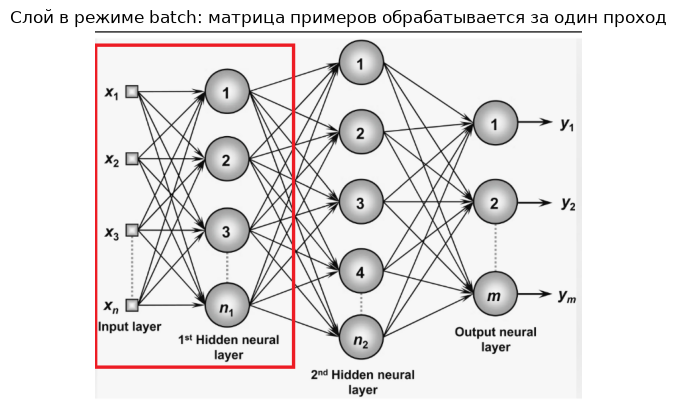

In [8]:
img = mpimg.imread('sources/img/Layer.png')
plt.imshow(img)
plt.title('Слой в режиме batch: матрица примеров обрабатывается за один проход')
plt.axis('off')
plt.show()

In [9]:
class Layer:
  def __init__(self, weights, biases):
    self.weights = weights
    self.biases = biases

  def forward(self, inputs):
    return inputs @ self.weights.T + self.biases

In [10]:
inputs1 = torch.tensor([[1, 2, 3, 2.5], [2, 5, -1, 2], [-1.5, 2.7, 3.3, -0.8]])
weights1 = torch.tensor([[0.2, 0.8, -0.5, 1.0],
           [0.5, -0.91, 0.26, -0.5],
           [-0.26, -0.27, 0.17, 0.87]])
biases1 = torch.tensor([2.0, 3.0, 0.5])

weights2 = torch.tensor([[.1, -.14, .5], [-.5, .12, -.33], [-.44, .73, -.13]])
biases2 = torch.tensor([-1, 2, -.5])

layer1 = Layer(weights1, biases1)
hidden_input = layer1.forward(inputs1)

layer2 = Layer(weights2, biases2)
output = layer2.forward(hidden_input)
output

tensor([[ 0.5031, -1.0419, -2.0388],
        [ 0.2434, -2.7332, -5.7633],
        [-0.9931,  1.4125, -0.3565]])

## Слой (случайная инициализация)

При построении сети веса обычно инициализируются случайным образом, а смещения — нулями. Размерности `weights` равны (число входов, число нейронов), чтобы при умножении `inputs @ weights` получить матрицу (примеры, нейроны).

Схема слоя остаётся той же; изменяется только способ задания параметров.

In [11]:
class Layer:
  def __init__(self, n_inputs, n_neurons):
    self.weights = torch.randn(n_inputs, n_neurons)
    self.biases = torch.zeros(n_neurons)

  def forward(self, inputs):
    return inputs @ self.weights + self.biases

In [12]:
inputs1 = torch.tensor([[1, 2, 3, 2.5], [2, 5, -1, 2], [-1.5, 2.7, 3.3, -0.8]])
layer = Layer(4, 6)
out = layer.forward(inputs1)
out

tensor([[ 5.3381,  0.5717,  3.1920, -5.6590,  1.9681, -2.8114],
        [ 6.8278,  2.8898, -0.9498,  1.2494, -1.0215,  0.0933],
        [ 8.8062,  0.1122, -9.9917, -4.4805,  7.1636, -5.0722]])

## Функции активации

Функция активации - это нелинейное преобразование выхода нейрона, без которого сеть сводится к одной линейной операции.

Ниже рассмотрены две частые функции активации: ReLU и softmax. ReLU поэлементно обнуляет отрицательные значения, а softmax превращает вектор логитов в вероятностное распределение.

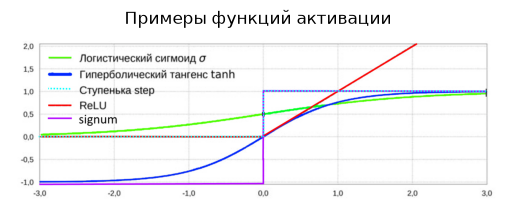

In [13]:
img = mpimg.imread('sources/img/Act.png')
plt.imshow(img)
plt.title('Примеры функций активации')
plt.axis('off')
plt.show()

ReLU - это функция активации $f(x)=\max(0,x)$, обнуляющая отрицательные входы.

Код ниже демонстрирует поэлементное применение ReLU к выходу случайного слоя; отрицательные элементы заменены нулями.

In [14]:
class ReLU:
  def forward(self, inputs):
    return inputs.clip(min=0)

In [15]:
ReLU().forward(out)

tensor([[5.3381, 0.5717, 3.1920, 0.0000, 1.9681, 0.0000],
        [6.8278, 2.8898, 0.0000, 1.2494, 0.0000, 0.0933],
        [8.8062, 0.1122, 0.0000, 0.0000, 7.1636, 0.0000]])

Softmax - это функция активации, преобразующая вектор произвольных чисел в распределение вероятностей по классам.

Формула softmax: $\mathrm{softmax}(z_i) = \dfrac{e^{z_i}}{\sum_j e^{z_j}}$. Реализация вычитает максимум для численной стабильности, затем нормирует экспоненты на сумму по строкам.

In [16]:
class Softmax:
  def forward(self, inputs):
    exp = torch.exp(inputs - inputs.max(dim=1, keepdim=True).values)
    probs = exp / exp.sum(dim=1, keepdim=True)
    self.output = probs
    return probs

  def backward(self, dvalues):
    with torch.no_grad():
      self.dinputs = self.output * (dvalues - torch.sum(dvalues * self.output, dim=1, keepdim=True))

In [17]:
Softmax().forward(out)

tensor([[8.6195e-01, 7.3362e-03, 1.0080e-01, 1.4439e-05, 2.9644e-02, 2.4900e-04],
        [9.7536e-01, 1.9006e-02, 4.0869e-04, 3.6854e-03, 3.8040e-04, 1.1598e-03],
        [8.3777e-01, 1.4041e-04, 5.7455e-09, 1.4217e-06, 1.6209e-01, 7.8674e-07]])

## Функции потерь

Функция потерь - это скалярная мера расхождения между предсказанием модели и истинным ответом, минимизируемая при обучении.

MSE применяется в задачах регрессии и штрафует большие отклонения сильнее малых; категориальная кросс-энтропия измеряет качество вероятностей, присвоенных правильным классам.

Функция потерь MSE: $\mathrm{MSE} = \dfrac{1}{n}\sum_i (y_i - \hat{y}_i)^2$.

Функция потерь Categorical Cross-Entropy: $L = -\dfrac{1}{n}\sum_i \log \hat{y}_{i, y_i}$.

In [18]:
inputs1 = torch.tensor([[1, 2, 3, 2.5], [2, 5, -1, 2], [-1.5, 2.7, 3.3, -0.8]])
layer = Layer(4, 1)
out = layer.forward(inputs1)
out

tensor([[ 0.1773],
        [ 3.7467],
        [-1.8365]])

Среднеквадратичная ошибка (MSE) - это функция потерь, равная среднему квадрату разности предсказаний и истинных значений.

In [19]:
class MSELoss:
  def forward(self, y_pred, y_true):
    return torch.mean(torch.pow(y_pred - y_true, 2))

In [20]:
y_true = torch.tensor([2, 3, 4]).view(-1, 1)
MSELoss().forward(out, y_true)

tensor(12.6481)

Категориальная кросс-энтропия - это функция потерь, равная среднему отрицательному логарифму вероятности, которую модель присвоила правильному классу.

In [21]:
class CategoricalCrossentropyLoss:
  def forward(self, y_pred, y_true):
    self.y_pred_clipped = torch.clamp(y_pred, min=1e-12)
    correct_conf = self.y_pred_clipped.gather(dim=1, index=y_true.view(-1, 1))
    neglog = -torch.log(correct_conf)
    return torch.mean(neglog)

  def backward(self, dvalues, y_true):
    with torch.no_grad():
      samples = dvalues.size(0)
      y_true_one_hot = torch.zeros_like(dvalues)
      y_true_one_hot.scatter_(1, y_true.view(-1, 1), 1)
      self.dinputs = (dvalues - y_true_one_hot) / samples

In [22]:
inputs1 = torch.tensor([[1, 2, 3, 2.5], [2, 5, -1, 2], [-1.5, 2.7, 3.3, -0.8]])
layer = Layer(4, 3)
out = layer.forward(inputs1)
out = Softmax().forward(out)
out

tensor([[1.7205e-01, 7.2561e-01, 1.0234e-01],
        [9.9386e-01, 3.1911e-04, 5.8170e-03],
        [9.9578e-01, 1.9644e-04, 4.0239e-03]])

In [23]:
y_true = torch.tensor([1, 0, 0])
CategoricalCrossentropyLoss().forward(out, y_true)

tensor(0.1104)

## Оптимизация SGD (стохастический градиентный спуск)

Градиентный спуск - это итерационный метод оптимизации, на каждом шаге сдвигающий параметры против градиента функции потерь.

Стохастическим градиентным спуском (SGD) называют шаг спуска по оценке градиента на одном примере или малом батче; эпохой называют один проход по всей обучающей выборке; скоростью обучения (learning rate, lr) называют множитель шага, определяющий величину изменения весов за итерацию.

Ниже сначала рассмотрен одноэлементный SGD для одного нейрона, затем — пакетный вариант.

#### Модифицируем класс Neuron

Сделаем так, чтобы веса нейрона инициализировались из стандартного нормального распределения.

In [24]:
from sklearn.datasets import make_regression

X, y, coef = make_regression(n_features=4, n_informative=4, coef=True, bias=0.5)
X = torch.from_numpy(X).to(dtype=torch.float32)
y = torch.from_numpy(y).to(dtype=torch.float32)

Графом вычислений называют представление вычисления выхода сети и её производных как последовательности элементарных операций.

Обратным распространением ошибки (backpropagation) называют применение правила дифференцирования сложной функции в обратном порядке — от функции потерь к входам — для вычисления градиентов по всем параметрам сети.

На схеме ниже показан вычислительный граф одноэлементного нейрона: стрелки вперёд — предсказание, стрелки назад — передача градиентов к параметрам.

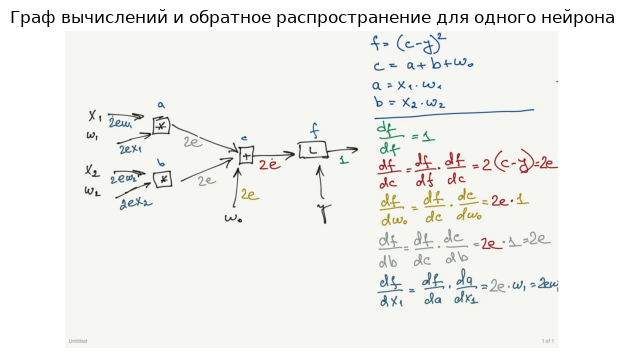

In [25]:
img = mpimg.imread('sources/img/back.png')
plt.imshow(img)
plt.title('Граф вычислений и обратное распространение для одного нейрона')
plt.axis('off')
plt.show()

In [26]:
class Neuron:
  def __init__(self, n_inputs):
    self.weights = torch.randn(n_inputs)
    self.bias = torch.randn(1)

  def forward(self, input):
    self.input = input
    return torch.dot(self.weights, input) + self.bias

  def backward(self, dvalue):
    self.dweights = dvalue * self.input
    self.dinput = dvalue * self.weights
    self.dbias = dvalue


class Loss:
  def forward(self, y_pred, y_true):
    return (y_pred - y_true) ** 2

  def backward(self, y_pred, y_true):
    self.dinput = 2 * (y_pred - y_true)

In [27]:
neuron = Neuron(4)
loss = Loss()

lr = 0.1

losses = []
for epoch in range(100):
  for x_example, y_example in zip(X, y):
    y_pred = neuron.forward(x_example)
    l = loss.forward(y_pred, y_example)
    losses.append(l)

    loss.backward(y_pred, y_example)
    neuron.backward(loss.dinput)

    neuron.weights -= lr * neuron.dweights
    neuron.bias -= lr * neuron.dbias

График ниже показывает значение MSE на каждом шаге стохастического градиентного спуска. Убывающая кривая свидетельствует о сходимости: веса нейрона постепенно приближаются к значениям, минимизирующим ошибку.

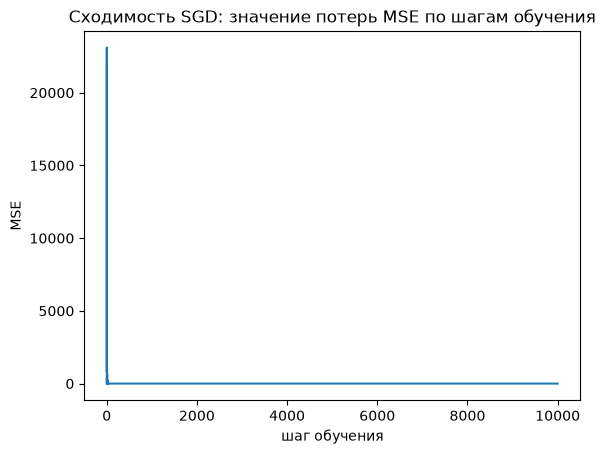

In [28]:
plt.plot(losses)
plt.title('Сходимость SGD: значение потерь MSE по шагам обучения')
plt.xlabel('шаг обучения')
plt.ylabel('MSE')
plt.show()

In [29]:
neuron.weights, neuron.bias

(tensor([ 5.1207, 85.7462,  5.1188, 17.4738]), tensor([0.5000]))

#### Используем пакетный градиентный спуск (batch SGD + neuron)

In [30]:
class Neuron:
  def __init__(self, n_inputs):
    self.weights = torch.randn(n_inputs, requires_grad=False)
    self.bias = torch.tensor(0.0, requires_grad=False)

  def forward(self, inputs):
    self.inputs = inputs
    return inputs @ self.weights + self.bias  # веса - вектор (n_inputs,), транспонировать не нужно

  def backward(self, dvalues):
    with torch.no_grad():
      self.dweights = self.inputs.T.mv(dvalues)
      self.dbiases = dvalues.sum()


class MSELossNeuron:
  def forward(self, y_pred, y_true):
    return torch.mean((y_pred - y_true) ** 2)

  def backward(self, y_pred, y_true):
    with torch.no_grad():
      self.dinputs = 2 * (y_pred - y_true) / len(y_pred)

Рисунки ниже иллюстрируют матричную форму прямого и обратного прохода для батча: матрица входов, вектор градиентов и правила обновления весов.

На первой схеме показан прямой проход и распространение ошибки назад к параметрам нейрона, на второй — детали вычисления градиентов по весам и смещению.

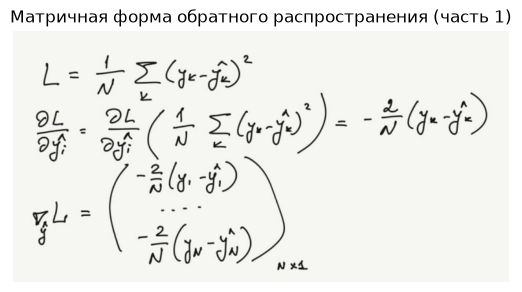

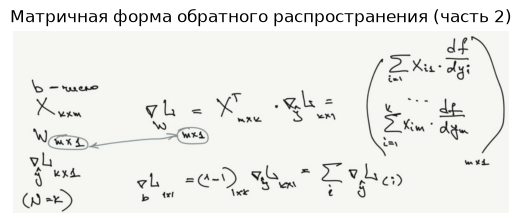

In [31]:
img = mpimg.imread('sources/img/back1.png')
plt.imshow(img)
plt.title('Матричная форма обратного распространения (часть 1)')
plt.axis('off')
plt.show()

img = mpimg.imread('sources/img/back2.png')
plt.imshow(img)
plt.title('Матричная форма обратного распространения (часть 2)')
plt.axis('off')
plt.show()

In [32]:
from sklearn.datasets import make_regression

X, y, coef = make_regression(n_features=4, n_informative=4, coef=True, bias=0.5)
X = torch.from_numpy(X).to(dtype=torch.float32)
y = torch.from_numpy(y).to(dtype=torch.float32)

In [33]:
neuron = Neuron(4)
loss = MSELossNeuron()

lr = 0.1

for epoch in range(100):
    y_pred = neuron.forward(X)
    l = loss.forward(y_pred, y)
    loss.backward(y_pred, y)
    neuron.backward(loss.dinputs)

    neuron.weights -= lr * neuron.dweights
    neuron.bias -= lr * neuron.dbiases
print(f'epoch {epoch} mean loss {l.mean()}')

epoch 99 mean loss 1.04400110778613e-09


In [34]:
neuron.weights, coef

(tensor([56.3938, 14.3980, 64.3273, 81.3811]),
 array([56.39384542, 14.39803109, 64.32730569, 81.38115797]))

### Разные варианты реализации нейросети

Полносвязным слоем (Dense) называют слой, в котором каждый нейрон связан со всеми входами.

Ниже собраны полносвязный слой `Dense`, функции активации ReLU и линейная активация, а также MSE-потеря с методами прямого и обратного прохода. Эти блоки используются далее для аппроксимации функций и классификации.

In [35]:
class Dense:
  def __init__(self, n_inputs, n_neurons):
    self.weights = torch.randn(n_inputs, n_neurons, requires_grad=False)
    self.biases = torch.zeros(n_neurons, requires_grad=False)

  def forward(self, inputs):
    self.inputs = inputs
    self.output = self.inputs @ self.weights + self.biases
    return self.output

  def backward(self, dvalues):
    with torch.no_grad():
      self.dweights = self.inputs.T @ dvalues
      self.dbiases = torch.sum(dvalues, dim=0)
      self.dinputs = dvalues @ self.weights.T

class Activation_ReLU:
  def forward(self, inputs):
    self.inputs = inputs
    self.output = inputs.clip(min=0)
    return self.output

  def backward(self, dvalues):
    with torch.no_grad():
      self.dinputs = dvalues.clone()
      self.dinputs[self.inputs <= 0] = 0

class Activation_Linear:
  def forward(self, inputs):
    self.inputs = inputs
    self.output = inputs
    return self.output

  def backward(self, dvalues):
    with torch.no_grad():
      self.dinputs = dvalues.clone()

class Loss:
  def calculate(self, output, y):
    sample_losses = self.forward(output, y)
    data_loss = sample_losses.mean()
    return data_loss

class MSELoss(Loss):
  def forward(self, y_pred, y_true):
    sample_losses = torch.mean((y_true - y_pred) ** 2, dim=1)
    return sample_losses

  def backward(self, dvalues, y_true):
    with torch.no_grad():
      self.dinputs = -2 * (y_true - dvalues) / len(dvalues)

class CategoricalCrossentropyLoss(Loss):
  def forward(self, y_pred, y_true):
    self.y_pred_clipped = torch.clamp(y_pred, min=1e-12)
    correct_conf = self.y_pred_clipped.gather(dim=1, index=y_true.view(-1, 1))
    neglog = -torch.log(correct_conf)
    return neglog.squeeze()

  def backward(self, dvalues, y_true):
    with torch.no_grad():
      samples = dvalues.size(0)
      y_true_one_hot = torch.zeros_like(dvalues)
      y_true_one_hot.scatter_(1, y_true.view(-1, 1), 1)
      self.dinputs = (dvalues - y_true_one_hot) / samples

Линейная активация просто возвращает свой вход, поэтому её график — прямая линия $y=x$, а градиент при обратном проходе передаётся без изменений.

Схема ниже иллюстрирует линейную функцию активации.

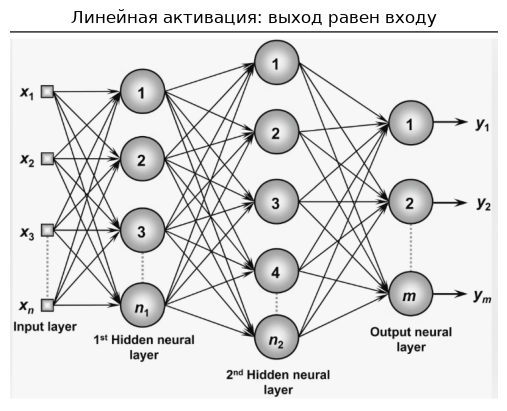

In [36]:
img = mpimg.imread('sources/img/Linear.png')
plt.imshow(img)
plt.title('Линейная активация: выход равен входу')
plt.axis('off')
plt.show()

In [37]:
from sklearn.datasets import make_regression

X, y, coef = make_regression(n_features=4, n_informative=4, coef=True, bias=0.5)
X = torch.from_numpy(X).to(dtype=torch.float32)
y = torch.from_numpy(y).to(dtype=torch.float32).view(-1, 1)

In [38]:
fc1 = Dense(4, 1)
loss = MSELoss()
lr = 0.1

for epoch in range(100):
  out = fc1.forward(X)
  data_loss = loss.calculate(out, y.view(-1, 1))
  print(f'epoch {epoch} mean loss {data_loss}')
  loss.backward(out, y.view(-1, 1))
  fc1.backward(loss.dinputs)

  fc1.weights -= lr * fc1.dweights
  fc1.biases -= lr * fc1.dbiases

epoch 0 mean loss 6407.61083984375
epoch 1 mean loss 3996.096923828125
epoch 2 mean loss 2521.309326171875
epoch 3 mean loss 1609.29150390625
epoch 4 mean loss 1038.783203125
epoch 5 mean loss 677.7449340820312
epoch 6 mean loss 446.63531494140625
epoch 7 mean loss 297.0482177734375
epoch 8 mean loss 199.20484924316406
epoch 9 mean loss 134.57843017578125
epoch 10 mean loss 91.5091781616211
epoch 11 mean loss 62.57493209838867
epoch 12 mean loss 42.99773406982422
epoch 13 mean loss 29.66863250732422
epoch 14 mean loss 20.544160842895508
epoch 15 mean loss 14.268742561340332
epoch 16 mean loss 9.935522079467773
epoch 17 mean loss 6.933195114135742
epoch 18 mean loss 4.846976280212402
epoch 19 mean loss 3.3937833309173584
epoch 20 mean loss 2.379413366317749
epoch 21 mean loss 1.6701222658157349
epoch 22 mean loss 1.1733945608139038
epoch 23 mean loss 0.8251007199287415
epoch 24 mean loss 0.5806049108505249
epoch 25 mean loss 0.40882232785224915
epoch 26 mean loss 0.2880241870880127
epoc

In [39]:
fc1.weights, coef

(tensor([[38.8836],
         [ 6.6220],
         [68.9662],
         [ 9.1230]]),
 array([38.88358114,  6.62197415, 68.96619048,  9.12296845]))

In [40]:
from sklearn.datasets import make_regression

X, y, coef = make_regression(n_features=4, n_informative=4, coef=True, bias=0.5)
X = torch.from_numpy(X).to(dtype=torch.float32)
y = torch.from_numpy(y).to(dtype=torch.float32).view(-1, 1)

In [41]:
X = torch.linspace(-1, 1, 100).view(-1, 1)
y = X.pow(2) + 0.2 * torch.rand(X.size())

In [42]:
fc1 = Dense(1, 10)
relu1 = Activation_ReLU()
fc2 = Dense(10, 1)

loss = MSELoss()
lr = 0.02

ys = []
for epoch in range(2001):
  out = fc1.forward(X)
  out = relu1.forward(out)
  out = fc2.forward(out)

  data_loss = loss.calculate(out, y)
  if epoch % 200 == 0:
    print(f'epoch {epoch} mean loss {data_loss}')
    ys.append(out)
  loss.backward(out, y)
  fc2.backward(loss.dinputs)
  relu1.backward(fc2.dinputs)
  fc1.backward(relu1.dinputs)

  fc1.weights -= lr * fc1.dweights
  fc1.biases -= lr * fc1.dbiases

  fc2.weights -= lr * fc2.dweights
  fc2.biases -= lr * fc2.dbiases

epoch 0 mean loss 0.1715170294046402
epoch 200 mean loss 0.009034658782184124
epoch 400 mean loss 0.006516847759485245
epoch 600 mean loss 0.006184748373925686
epoch 800 mean loss 0.005973390769213438
epoch 1000 mean loss 0.005750329699367285
epoch 1200 mean loss 0.0055487859062850475
epoch 1400 mean loss 0.0053865606896579266
epoch 1600 mean loss 0.005272748880088329
epoch 1800 mean loss 0.005199445877224207
epoch 2000 mean loss 0.005149168893694878


На рисунке ниже показаны снимки аппроксимации параболы $y=x^2$ с шагом 200 эпох. Оранжевые точки — зашумлённые исходные данные, зелёная линия — предсказание сети; по мере обучения ломаная ReLU-аппроксимация приближается к параболе.

На каждом подграфике по оси X отложены значения входа, а по оси Y — значение целевой функции и предсказание сети.

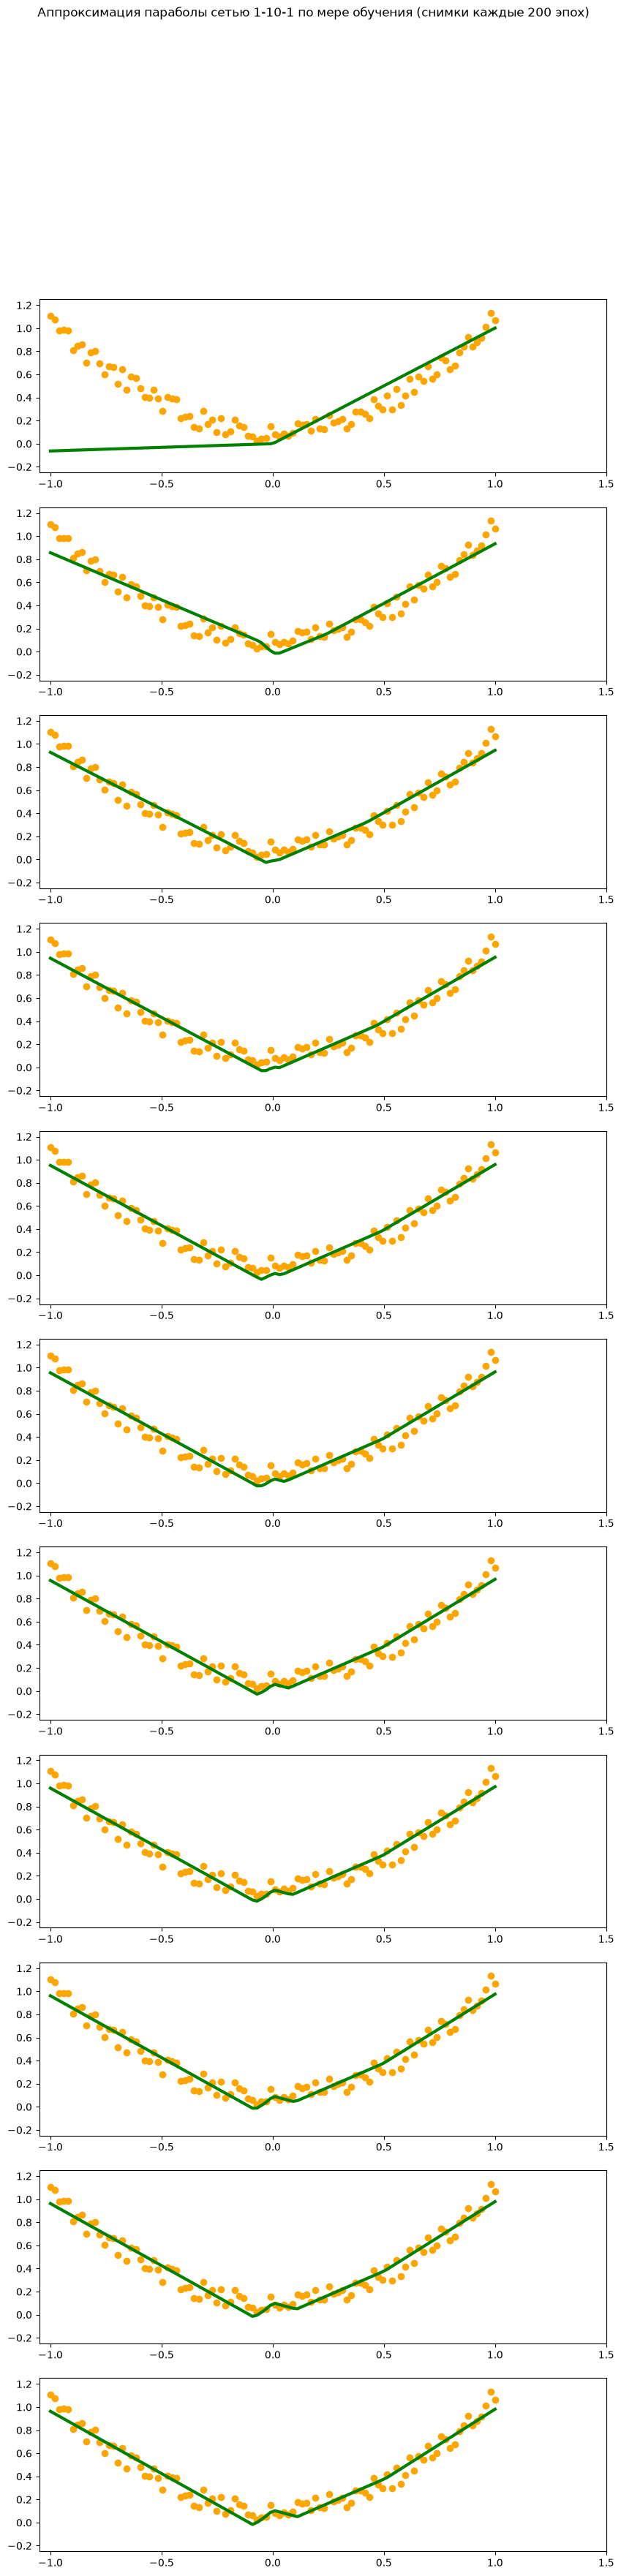

In [43]:
fig, axs = plt.subplots(len(ys), 1, figsize=(10, 40))
for ax, y_ in zip(axs, ys):
  ax.scatter(X.numpy(), y.numpy(), color = "orange")
  ax.plot(X.numpy(), y_.numpy(), 'g-', lw=3)
  ax.set_xlim(-1.05, 1.5)
  ax.set_ylim(-0.25, 1.25)
fig.suptitle('Аппроксимация параболы сетью 1-10-1 по мере обучения (снимки каждые 200 эпох)')
plt.show()

## Классификация: набор данных Breast Cancer

В заключительном эксперименте обучим полносвязную сеть из двух слоев классифицировать опухоли по 30 числовым признакам из набора `load_breast_cancer`. Данные разделены на обучающую (70%) и тестовую (30%) выборки с фиксированным `random_state=42`.

На графике ниже слева показано изменение функции потерь CCE на обучающей и тестовой выборках, а справа — доля правильных ответов на тестовой выборке по эпохам. Обе кривые позволяют оценить сходимость обучения и отсутствие сильного переобучения.

In [44]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

data = load_breast_cancer()
X = torch.from_numpy(data.data).to(dtype=torch.float32)
y = torch.from_numpy(data.target).to(dtype=torch.long)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [45]:
torch.manual_seed(42)

fc1 = Dense(30, 16)
relu1 = Activation_ReLU()
fc2 = Dense(16, 2)
softmax = Softmax()
loss_fn = CategoricalCrossentropyLoss()

lr = 0.001
epochs = 200

train_losses = []
val_losses = []
val_accuracies = []

for epoch in range(epochs):
    out = fc1.forward(X_train)
    out = relu1.forward(out)
    out = fc2.forward(out)
    out = softmax.forward(out)

    train_loss = loss_fn.calculate(out, y_train)

    loss_fn.backward(out, y_train)
    fc2.backward(loss_fn.dinputs)
    relu1.backward(fc2.dinputs)
    fc1.backward(relu1.dinputs)

    fc1.weights -= lr * fc1.dweights
    fc1.biases -= lr * fc1.dbiases
    fc2.weights -= lr * fc2.dweights
    fc2.biases -= lr * fc2.dbiases

    with torch.no_grad():
        val_out = fc1.forward(X_test)
        val_out = relu1.forward(val_out)
        val_out = fc2.forward(val_out)
        val_out = softmax.forward(val_out)
        val_loss = loss_fn.calculate(val_out, y_test)
        predictions = torch.argmax(val_out, dim=1)
        val_acc = (predictions == y_test).to(torch.float32).mean().item()

    train_losses.append(train_loss.item())
    val_losses.append(val_loss.item())
    val_accuracies.append(val_acc)

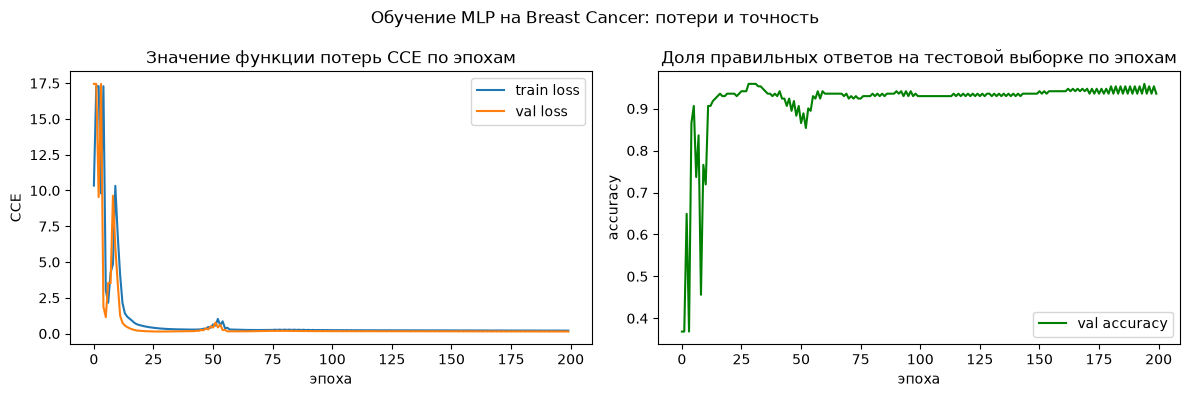

In [46]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(train_losses, label='train loss')
ax1.plot(val_losses, label='val loss')
ax1.set_title('Значение функции потерь CCE по эпохам')
ax1.set_xlabel('эпоха')
ax1.set_ylabel('CCE')
ax1.legend()

ax2.plot(val_accuracies, label='val accuracy', color='green')
ax2.set_title('Доля правильных ответов на тестовой выборке по эпохам')
ax2.set_xlabel('эпоха')
ax2.set_ylabel('accuracy')
ax2.legend()

fig.suptitle('Обучение MLP на Breast Cancer: потери и точность')
plt.tight_layout()
plt.show()

Одной accuracy недостаточно для полной оценки классификатора, поэтому дополнительно вычисляются метрики по confusion-матрице (положительный класс — 1, то есть benign).

Precision (точность) - это доля объектов, отнесённых моделью к положительному классу, которые действительно ему принадлежат.

Recall (полнота) - это доля объектов положительного класса, которые модель правильно распознала.

F1-мера - это среднее гармоническое точности и полноты, объединяющее обе метрики в одно число.

В текстовом выводе ниже приведены accuracy, precision, recall и F1-мера на тестовой выборке, а также состав confusion-матрицы: TP и TN — правильные ответы, FP — ложноположительные, FN — ложноотрицательные.

In [47]:
with torch.no_grad():
    train_out = fc1.forward(X_train)
    train_out = relu1.forward(train_out)
    train_out = fc2.forward(train_out)
    train_out = softmax.forward(train_out)
    train_acc = (torch.argmax(train_out, dim=1) == y_train).to(torch.float32).mean().item()

    test_out = fc1.forward(X_test)
    test_out = relu1.forward(test_out)
    test_out = fc2.forward(test_out)
    test_out = softmax.forward(test_out)
    test_pred = torch.argmax(test_out, dim=1)
    test_acc = (test_pred == y_test).to(torch.float32).mean().item()

    # Составляющие confusion-матрицы (положительный класс — 1, benign)
    tp = ((test_pred == 1) & (y_test == 1)).sum().item()
    fp = ((test_pred == 1) & (y_test == 0)).sum().item()
    fn = ((test_pred == 0) & (y_test == 1)).sum().item()
    tn = ((test_pred == 0) & (y_test == 0)).sum().item()
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    f1 = 2 * precision * recall / (precision + recall)

print(f'Final train accuracy: {train_acc:.4f}')
print(f'Final test accuracy: {test_acc:.4f}')
print(f'Test precision: {precision:.4f}')
print(f'Test recall:    {recall:.4f}')
print(f'Test F1:        {f1:.4f}')
print(f'Confusion matrix: TP={tp} FP={fp} FN={fn} TN={tn}')

Final train accuracy: 0.9322
Final test accuracy: 0.9357
Test precision: 0.9292
Test recall:    0.9722
Test F1:        0.9502
Confusion matrix: TP=105 FP=8 FN=3 TN=55


## Выводы

- Реализованы базовые блоки нейросети: нейрон, полносвязный слой, функции активации ReLU и softmax, функции потерь MSE и категориальной кросс-энтропии.
- Показано обучение одного нейрона и многослойной сети методом обратного распространения ошибки; в обоих случаях значение потерь убывает, а веса приближаются к целевым.
- Сеть 1-10-1 с ReLU успешно аппроксимирует параболу $y=x^2$ с шумом.
- На наборе Breast Cancer двухслойная сеть Dense(30,16) → ReLU → Dense(16,2) → Softmax достигает accuracy около 0.93 на обучающей и 0.94 на тестовой выборках при `random_state=42` и `lr=0.001`; на тестовой выборке precision = 0.93, recall = 0.97, F1 = 0.95 (TP=105, FP=8, FN=3, TN=55), то есть сеть пропускает лишь около 3% злокачественных опухолей.
- На неотмасштабированных признаках большой learning rate (0.05) приводит к насыщению softmax и расхождению потерь до NaN, поэтому скорость обучения пришлось снизить до 0.001 — это иллюстрирует чувствительность градиентного спуска к масштабу признаков.

### Итоговые результаты классификации Breast Cancer

Обучение: `torch.manual_seed(42)`, разделение 70/30 (`random_state=42`), `lr=0.001`, 200 эпох. Метрики приведены на тестовой выборке (171 объект), положительный класс — 1 (benign).

| Метрика | Значение |
|---|---|
| Accuracy (train / test) | 0.9322 / 0.9357 |
| Precision | 0.9292 |
| Recall | 0.9722 |
| F1-мера | 0.9502 |
| Confusion matrix | TP=105, FP=8, FN=3, TN=55 |